# Retrieval Stack Comparison

Reads the results from `Retrieval_Stack_Benchmark.ipynb` and compares every arm on
every metric, both datasets, side by side.

Never averaged across datasets: NFCorpus has 323 queries with human qrels, LUMEN has
30 with LLM-generated ones.

## Setup

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

_ROWS = [
 ("nfcorpus","s-pubmedbert","none",0.3121,0.5215,0.0495,0.0886,0.1056,0.1416,0.0227),
 ("nfcorpus","s-pubmedbert","medcpt",0.3619,0.5657,0.0614,0.1175,0.1443,0.1779,2799.1759),
 ("nfcorpus","s-pubmedbert","rerank-v3.5",0.3617,0.5771,0.0663,0.1145,0.1388,0.1751,543.0735),
 ("nfcorpus","s-pubmedbert","rerank-v4.0-fast",0.3860,0.6026,0.0746,0.1274,0.1534,0.1844,547.3456),
 ("nfcorpus","s-pubmedbert","rerank-v4.0-pro",0.4110,0.6292,0.0798,0.1354,0.1610,0.1987,907.2815),
 ("nfcorpus","cohere-embed-v4","none",0.4016,0.6088,0.0664,0.1272,0.1580,0.2068,0.0254),
 ("nfcorpus","cohere-embed-v4","medcpt",0.3767,0.5792,0.0634,0.1187,0.1458,0.1925,2978.5434),
 ("nfcorpus","cohere-embed-v4","rerank-v3.5",0.3720,0.5904,0.0677,0.1177,0.1390,0.1870,558.8612),
 ("nfcorpus","cohere-embed-v4","rerank-v4.0-fast",0.4074,0.6224,0.0763,0.1311,0.1630,0.2003,547.2168),
 ("nfcorpus","cohere-embed-v4","rerank-v4.0-pro",0.4347,0.6483,0.0771,0.1398,0.1667,0.2128,913.8349),
 ("lumen","s-pubmedbert","none",0.6179,0.9722,0.0427,0.1235,0.1912,0.3932,0.0672),
 ("lumen","s-pubmedbert","medcpt",0.5889,0.9833,0.0429,0.1244,0.2014,0.3927,802.0019),
 ("lumen","s-pubmedbert","rerank-v3.5",0.7744,0.9733,0.0427,0.1264,0.2089,0.4241,403.9508),
 ("lumen","s-pubmedbert","rerank-v4.0-fast",0.8657,0.9722,0.0427,0.1281,0.2135,0.4321,414.8012),
 ("lumen","s-pubmedbert","rerank-v4.0-pro",0.9298,1.0000,0.0448,0.1343,0.2222,0.4381,646.0145),
 ("lumen","cohere-embed-v4","none",0.6183,0.9833,0.0427,0.1120,0.1723,0.3030,0.0471),
 ("lumen","cohere-embed-v4","medcpt",0.5479,0.9583,0.0416,0.1126,0.1876,0.3140,1056.5462),
 ("lumen","cohere-embed-v4","rerank-v3.5",0.6511,0.9250,0.0401,0.1083,0.1797,0.3325,454.9012),
 ("lumen","cohere-embed-v4","rerank-v4.0-fast",0.7102,0.9028,0.0389,0.1110,0.1719,0.3282,447.6060),
 ("lumen","cohere-embed-v4","rerank-v4.0-pro",0.7356,0.8944,0.0371,0.1136,0.1774,0.3263,666.5856),
]
_COLS = ["dataset","embedder","reranker","nDCG@10","MRR@10","R@1","R@3","R@5","R@10","ms"]

# live kernel > saved CSV > built-in copy
try:
    combined = pd.concat([df_nf, df_lu], ignore_index=True); SOURCE = "kernel"
except NameError:
    try:
        combined = pd.read_csv("../results/combined_grid.csv"); SOURCE = "csv"
    except Exception:
        combined = pd.DataFrame(_ROWS, columns=_COLS); SOURCE = "built-in"

print(f"loaded from {SOURCE}  |  {len(combined)} arms")
combined

loaded from built-in  |  20 arms


,dataset,embedder,reranker,nDCG@10,MRR@10,R@1,R@3,R@5,R@10,ms
0,nfcorpus,s-pubmedbert,none,0.3121,0.5215,0.0495,0.0886,0.1056,0.1416,0.0227
1,nfcorpus,s-pubmedbert,medcpt,0.3619,0.5657,0.0614,0.1175,0.1443,0.1779,2799.1759
2,nfcorpus,s-pubmedbert,rerank-v3.5,0.3617,0.5771,0.0663,0.1145,0.1388,0.1751,543.0735
3,nfcorpus,s-pubmedbert,rerank-v4.0-fast,0.3860,0.6026,0.0746,0.1274,0.1534,0.1844,547.3456
4,nfcorpus,s-pubmedbert,rerank-v4.0-pro,0.4110,0.6292,0.0798,0.1354,0.1610,0.1987,907.2815
5,nfcorpus,cohere-embed-v4,none,0.4016,0.6088,0.0664,0.1272,0.1580,0.2068,0.0254
6,nfcorpus,cohere-embed-v4,medcpt,0.3767,0.5792,0.0634,0.1187,0.1458,0.1925,2978.5434
7,nfcorpus,cohere-embed-v4,rerank-v3.5,0.3720,0.5904,0.0677,0.1177,0.1390,0.1870,558.8612
8,nfcorpus,cohere-embed-v4,rerank-v4.0-fast,0.4074,0.6224,0.0763,0.1311,0.1630,0.2003,547.2168
9,nfcorpus,cohere-embed-v4,rerank-v4.0-pro,0.4347,0.6483,0.0771,0.1398,0.1667,0.2128,913.8349


## Theme

In [ ]:
THEMES = {
    "retro": dict(bg="#F5F5F5", panel="#FFFFFF", ink="#303841", muted="#76ABAE",
                  accent="#FF5722", deep="#303841", grid="#D8DCDE"),
    "navy":  dict(bg="#EAECF0", panel="#FFFFFF", ink="#000000", muted="#233D4D",
                  accent="#FE7F2D", deep="#233D4D", grid="#CBD1D9"),
}
THEME = "retro"          # <- "retro" or "navy"
T = THEMES[THEME]

C_EMB = {"s-pubmedbert": T["deep"],  "cohere-embed-v4": T["accent"]}
C_DS  = {"nfcorpus":     T["muted"], "lumen":           T["accent"]}
CMAP  = LinearSegmentedColormap.from_list("theme", [T["bg"], T["muted"], T["deep"]])
HATCH = "////"           # harmful bars: hatched, not a separate colour

plt.rcParams.update({
    "figure.dpi": 120, "figure.facecolor": T["bg"], "savefig.facecolor": T["bg"],
    "axes.facecolor": T["panel"], "axes.edgecolor": T["grid"],
    "axes.labelcolor": T["ink"], "text.color": T["ink"],
    "xtick.color": T["ink"], "ytick.color": T["ink"],
    "grid.color": T["grid"], "axes.grid": True, "grid.alpha": .55, "grid.linewidth": .7,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "legend.frameon": False, "hatch.linewidth": .8,
})
print(f"theme: {THEME}")

theme: retro


In [ ]:
RERANK_ORDER = ["none","medcpt","rerank-v3.5","rerank-v4.0-fast","rerank-v4.0-pro"]
EMB_ORDER    = ["s-pubmedbert","cohere-embed-v4"]
DATASETS     = [d for d in ["nfcorpus","lumen"] if d in set(combined.dataset)]
METRICS      = ["nDCG@10","MRR@10","R@1","R@3","R@5","R@10"]

SHORT = {"none":"none","medcpt":"medcpt","rerank-v3.5":"v3.5",
         "rerank-v4.0-fast":"v4-fast","rerank-v4.0-pro":"v4-pro"}

N_QUERIES      = {"nfcorpus":323, "lumen":30}
LUMEN_MED_REL  = 23                      # median relevant passages per LUMEN query
LUMEN_R10_CEIL = 10 / LUMEN_MED_REL      # hard cap on R@10

RERANK_ORDER = [r for r in RERANK_ORDER if r in set(combined.reranker)]
EMB_ORDER    = [e for e in EMB_ORDER    if e in set(combined.embedder)]

def piv(ds, metric="nDCG@10"):
    return (combined[combined.dataset == ds]
            .pivot(index="embedder", columns="reranker", values=metric)
            .reindex(index=EMB_ORDER, columns=RERANK_ORDER))

---
## 1 - nDCG@10 grid

All 10 arms. `none` = embedder ranking, no reranker.

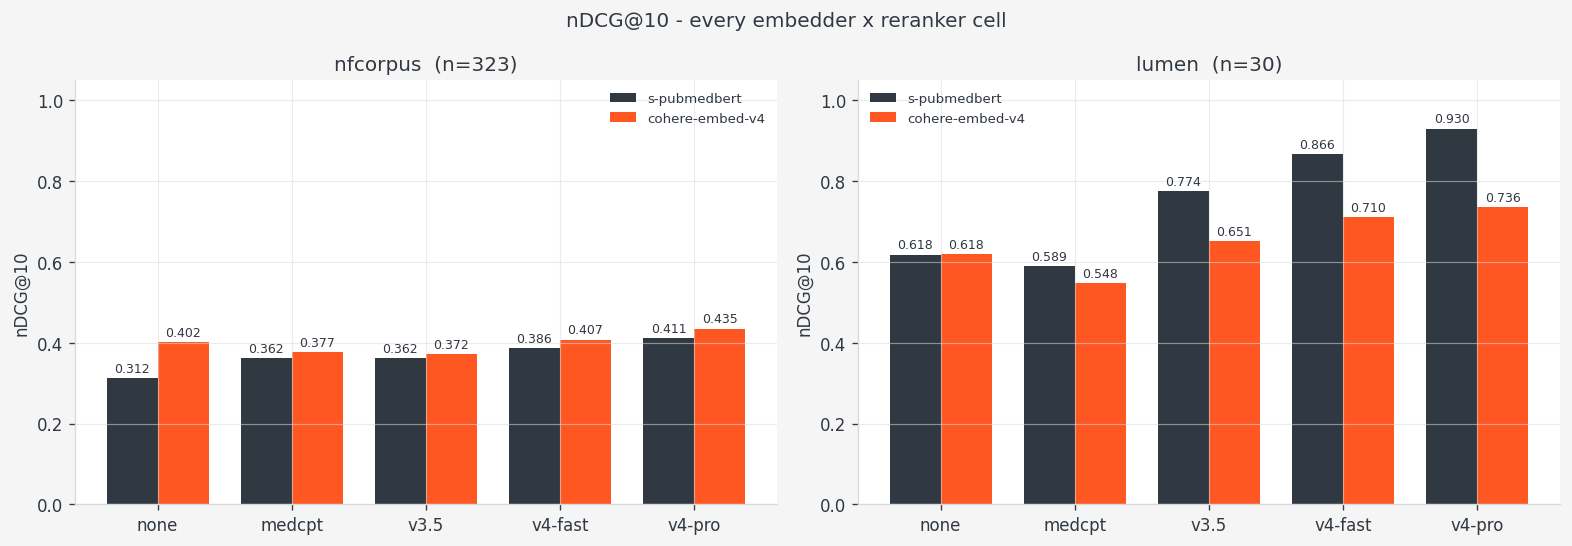

In [ ]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.6*len(DATASETS), 4.6), squeeze=False)
for ax, ds in zip(axes[0], DATASETS):
    p = piv(ds); xs = np.arange(len(RERANK_ORDER)); w = .38
    for i, emb in enumerate(EMB_ORDER):
        b = ax.bar(xs + i*w, p.loc[emb].values, w, color=C_EMB[emb], label=emb)
        ax.bar_label(b, fmt="%.3f", fontsize=7.5, padding=2, color=T["ink"])
    ax.set_xticks(xs + w/2); ax.set_xticklabels([SHORT[r] for r in RERANK_ORDER])
    ax.set_ylim(0, 1.05); ax.set_ylabel("nDCG@10")
    ax.set_title(f"{ds}  (n={N_QUERIES.get(ds,'?')})")
    ax.legend(fontsize=8)
fig.suptitle("nDCG@10 - every embedder x reranker cell", fontsize=12, color=T["ink"])
fig.tight_layout(); plt.show()

Embedder winner flips between datasets. Reranker order does not.

---
## 2 - All metrics

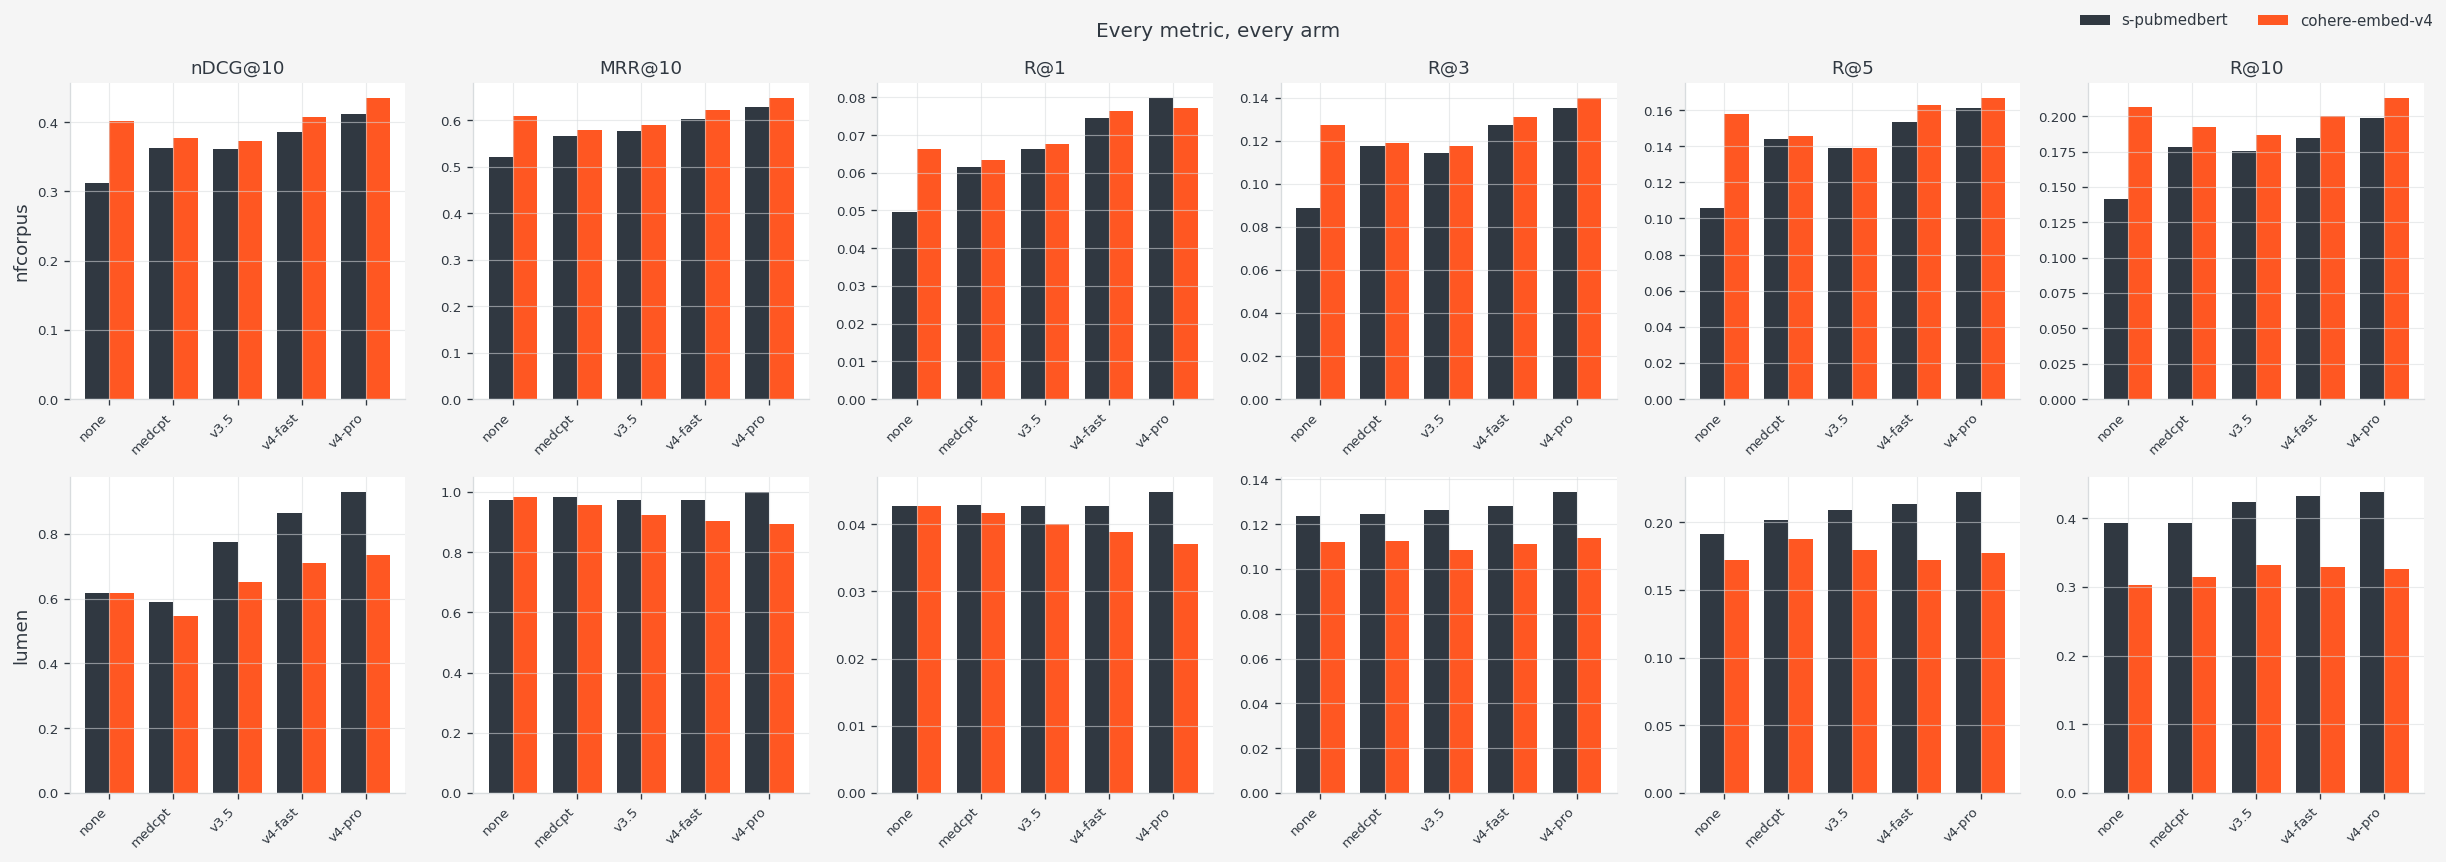

In [ ]:
fig, axes = plt.subplots(len(DATASETS), len(METRICS),
                         figsize=(3.4*len(METRICS), 3.6*len(DATASETS)), squeeze=False)
for r, ds in enumerate(DATASETS):
    for c, m in enumerate(METRICS):
        ax = axes[r, c]; p = piv(ds, m); xs = np.arange(len(RERANK_ORDER)); w = .38
        for i, emb in enumerate(EMB_ORDER):
            ax.bar(xs + i*w, p.loc[emb].values, w, color=C_EMB[emb],
                   label=emb if (r == 0 and c == 0) else None)
        ax.set_xticks(xs + w/2)
        ax.set_xticklabels([SHORT[x] for x in RERANK_ORDER], rotation=45, ha="right", fontsize=8)
        if r == 0: ax.set_title(m, fontsize=11)
        if c == 0: ax.set_ylabel(ds, fontsize=11)
        ax.tick_params(labelsize=8)
fig.legend(loc="upper right", fontsize=9, ncol=2)
fig.suptitle("Every metric, every arm", fontsize=12, color=T["ink"])
fig.tight_layout(); plt.show()

LUMEN MRR@10 and R@1 are flat - 29/30 queries already correct at rank 1. nDCG carries the signal.

---
## 3 - Reranker comparison

Change vs `none`. Hatched bars are below zero: worse than no reranker.

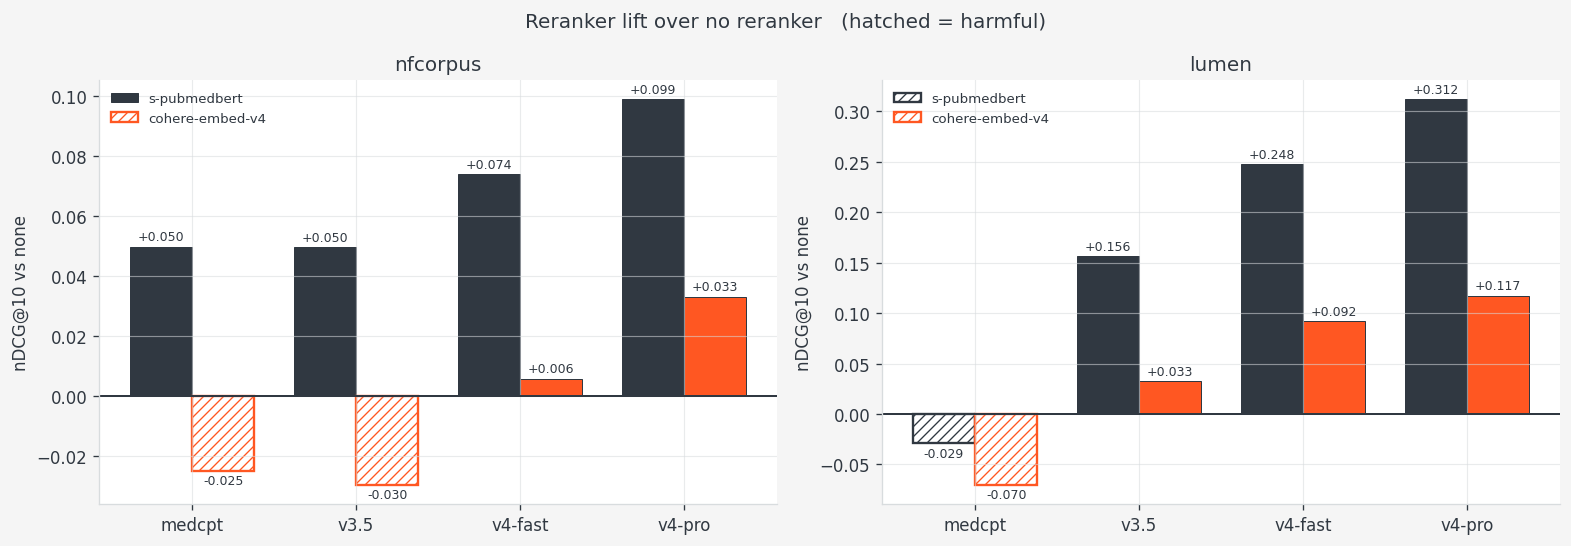

In [ ]:
rr = [r for r in RERANK_ORDER if r != "none"]
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.6*len(DATASETS), 4.6), squeeze=False)
for ax, ds in zip(axes[0], DATASETS):
    p = piv(ds); xs = np.arange(len(rr)); w = .38
    for i, emb in enumerate(EMB_ORDER):
        d = [p.loc[emb, r] - p.loc[emb, "none"] for r in rr]
        b = ax.bar(xs + i*w, d, w, color=C_EMB[emb], edgecolor=T["ink"], linewidth=.6,
                   label=emb, hatch=None)
        for bar, v in zip(b, d):
            if v < 0:
                bar.set_hatch(HATCH); bar.set_facecolor(T["panel"])
                bar.set_edgecolor(C_EMB[emb]); bar.set_linewidth(1.4)
        ax.bar_label(b, fmt="%+.3f", fontsize=7.5, padding=2, color=T["ink"])
    ax.axhline(0, color=T["ink"], lw=1.2)
    ax.set_xticks(xs + w/2); ax.set_xticklabels([SHORT[x] for x in rr])
    ax.set_ylabel("nDCG@10 vs none"); ax.set_title(ds)
    ax.legend(fontsize=8)
fig.suptitle("Reranker lift over no reranker   (hatched = harmful)", fontsize=12, color=T["ink"])
fig.tight_layout(); plt.show()

In [ ]:
lift = []
for ds in DATASETS:
    p = piv(ds)
    for emb in EMB_ORDER:
        for r in rr:
            lift.append({"dataset":ds, "embedder":emb, "reranker":SHORT[r],
                         "v": round(p.loc[emb,r] - p.loc[emb,"none"], 4)})
lift = pd.DataFrame(lift).pivot_table(index="reranker", columns=["dataset","embedder"], values="v")
lift["harmful"] = (lift < 0).sum(axis=1)
lift.reindex([SHORT[r] for r in rr])

dataset            lumen                     nfcorpus              harmful
embedder cohere-embed-v4 s-pubmedbert cohere-embed-v4 s-pubmedbert        
reranker                                                                  
medcpt           -0.0704      -0.0290         -0.0249       0.0498       3
v3.5              0.0328       0.1565         -0.0296       0.0496       1
v4-fast           0.0919       0.2478          0.0058       0.0739       0
v4-pro            0.1173       0.3119          0.0331       0.0989       0

`medcpt` loses to `none` in 3 of 4 columns and is the slowest arm. Rest: v3.5 < v4-fast < v4-pro.

---
## 4 - Embedder comparison

Same reranker, swap the embedder.

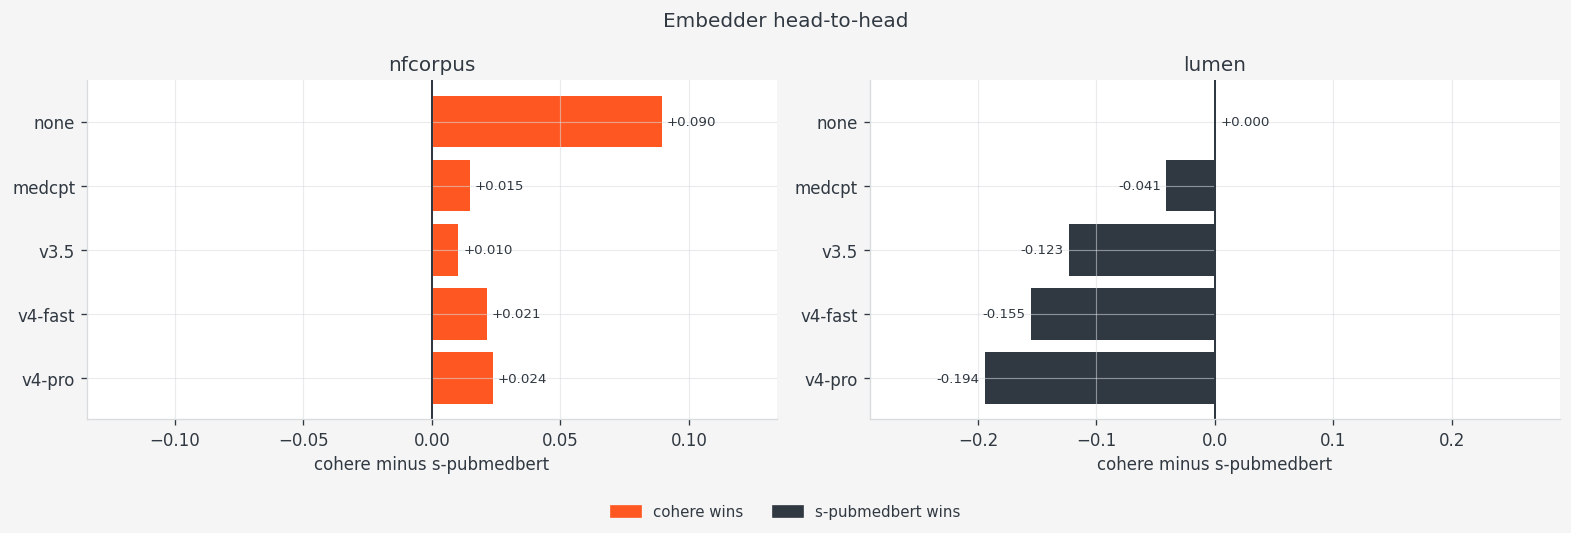

In [ ]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.6*len(DATASETS), 4.4), squeeze=False)
for ax, ds in zip(axes[0], DATASETS):
    p = piv(ds)
    d = [p.loc["cohere-embed-v4", r] - p.loc["s-pubmedbert", r] for r in RERANK_ORDER]
    b = ax.barh(range(len(d)), d,
                color=[C_EMB["cohere-embed-v4"] if v > 0 else C_EMB["s-pubmedbert"] for v in d])
    ax.bar_label(b, fmt="%+.3f", fontsize=8, padding=3, color=T["ink"])
    ax.set_yticks(range(len(d))); ax.set_yticklabels([SHORT[r] for r in RERANK_ORDER])
    ax.axvline(0, color=T["ink"], lw=1.2)
    ax.set_xlabel("cohere minus s-pubmedbert"); ax.set_title(ds); ax.invert_yaxis()
    lim = max(map(abs, d)) * 1.5; ax.set_xlim(-lim, lim)
fig.legend(handles=[Patch(color=C_EMB["cohere-embed-v4"], label="cohere wins"),
                    Patch(color=C_EMB["s-pubmedbert"],    label="s-pubmedbert wins")],
           loc="lower center", ncol=2, fontsize=9)
fig.suptitle("Embedder head-to-head", fontsize=12, color=T["ink"])
fig.tight_layout(rect=[0,.07,1,1]); plt.show()

cohere wins every matchup on nfcorpus. s-pubmedbert wins every matchup but `medcpt` on lumen, by wider margins.

---
## 5 - Quality vs latency

Up and left is better.

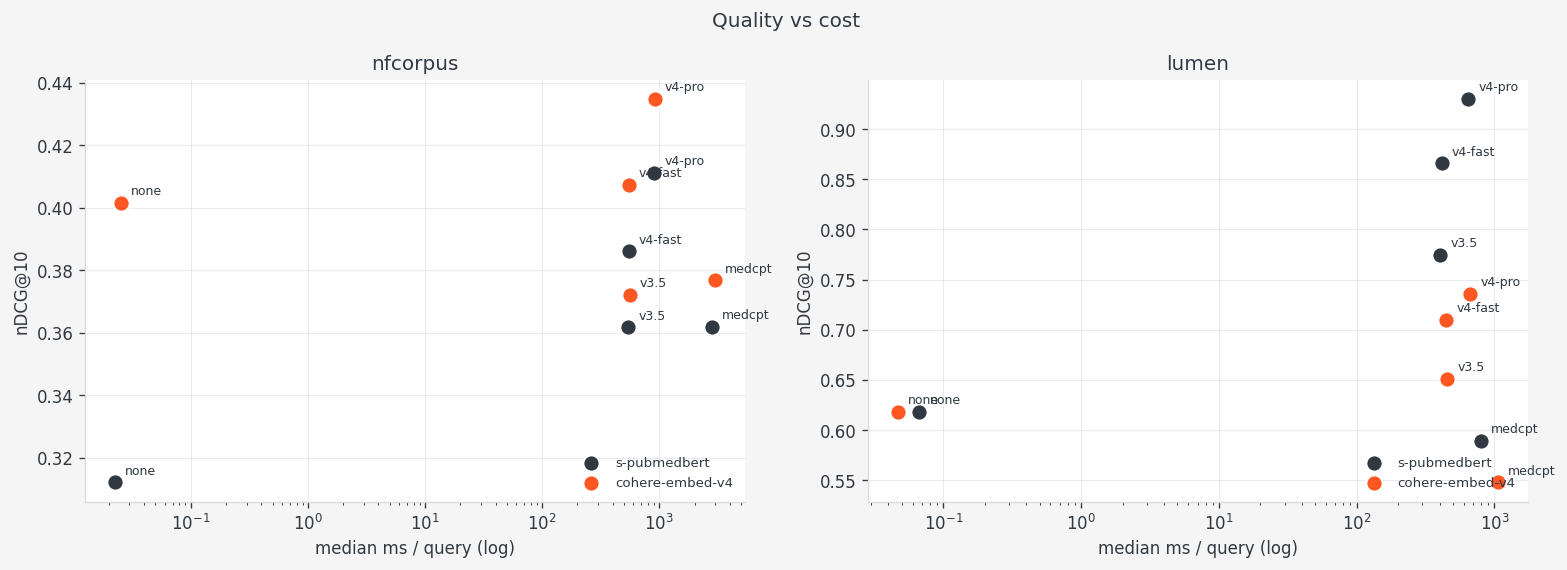

In [ ]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.6*len(DATASETS), 4.8), squeeze=False)
for ax, ds in zip(axes[0], DATASETS):
    sub = combined[combined.dataset == ds]
    for emb in EMB_ORDER:
        s = sub[sub.embedder == emb]
        ax.scatter(s["ms"].clip(lower=.02), s["nDCG@10"], s=95, color=C_EMB[emb],
                   edgecolor=T["panel"], linewidth=1.2, label=emb, zorder=3)
        for _, row in s.iterrows():
            ax.annotate(SHORT[row["reranker"]], (max(row["ms"], .02), row["nDCG@10"]),
                        textcoords="offset points", xytext=(6,5), fontsize=7.5, color=T["ink"])
    ax.set_xscale("log"); ax.set_xlabel("median ms / query (log)")
    ax.set_ylabel("nDCG@10"); ax.set_title(ds)
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Quality vs cost", fontsize=12, color=T["ink"])
fig.tight_layout(); plt.show()

In [ ]:
cost = combined.copy()
base = cost[cost.reranker == "none"].set_index(["dataset","embedder"])["nDCG@10"].rename("base")
cost = cost.join(base, on=["dataset","embedder"])
cost["gain"] = cost["nDCG@10"] - cost["base"]
cost["ms_per_pt"] = np.where(cost["gain"] > 0, cost["ms"] / (cost["gain"]*100), np.nan)
(cost[cost.reranker != "none"]
   .assign(reranker=lambda d: d.reranker.map(SHORT))
   .pivot_table(index="reranker", columns=["dataset","embedder"], values="ms_per_pt")
   .round(0).reindex([SHORT[r] for r in rr]))

dataset            lumen                     nfcorpus             
embedder cohere-embed-v4 s-pubmedbert cohere-embed-v4 s-pubmedbert
reranker                                                          
medcpt               NaN          NaN             NaN        562.0
v3.5               139.0         26.0             NaN        109.0
v4-fast             49.0         17.0           943.0         74.0
v4-pro              57.0         21.0           276.0         92.0

ms per 0.01 nDCG gained. Blank = no gain to price.

---
## 6 - Heatmap

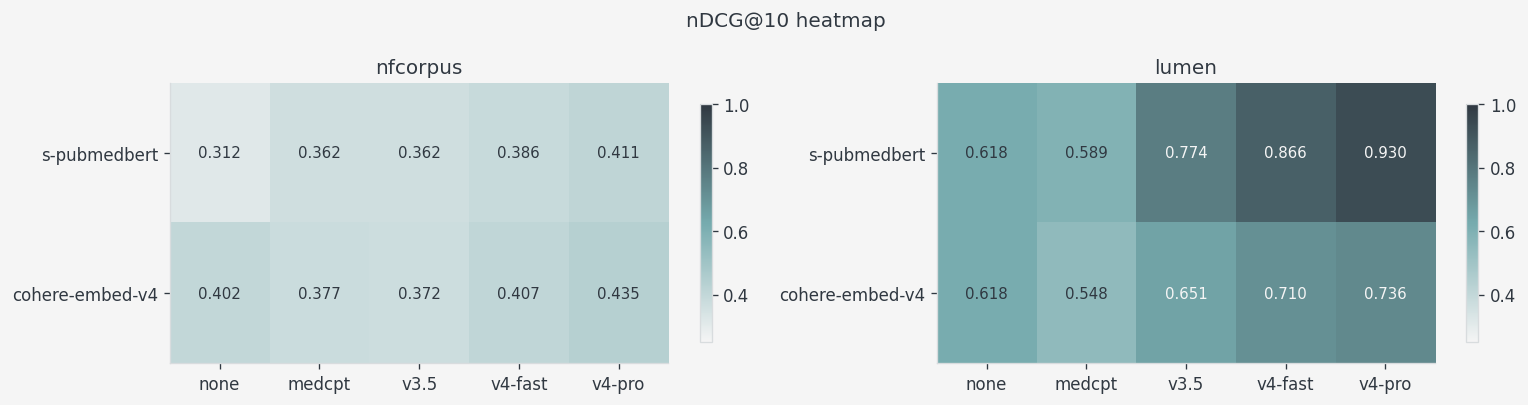

In [ ]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.6*len(DATASETS), 3.4), squeeze=False)
for ax, ds in zip(axes[0], DATASETS):
    p = piv(ds)
    im = ax.imshow(p.values, cmap=CMAP, vmin=.25, vmax=1.0, aspect="auto")
    ax.set_xticks(range(len(RERANK_ORDER))); ax.set_xticklabels([SHORT[r] for r in RERANK_ORDER])
    ax.set_yticks(range(len(EMB_ORDER)));    ax.set_yticklabels(EMB_ORDER)
    for i in range(p.shape[0]):
        for j in range(p.shape[1]):
            v = p.values[i, j]
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                    color=T["bg"] if v > .62 else T["ink"])
    ax.set_title(ds); ax.grid(False)
    cb = fig.colorbar(im, ax=ax, shrink=.85); cb.outline.set_edgecolor(T["grid"])
fig.suptitle("nDCG@10 heatmap", fontsize=12, color=T["ink"])
fig.tight_layout(); plt.show()

---
## 7 - Recall curves

Median 23 relevant passages per LUMEN query, 10 slots -> R@10 cannot exceed ~0.43.

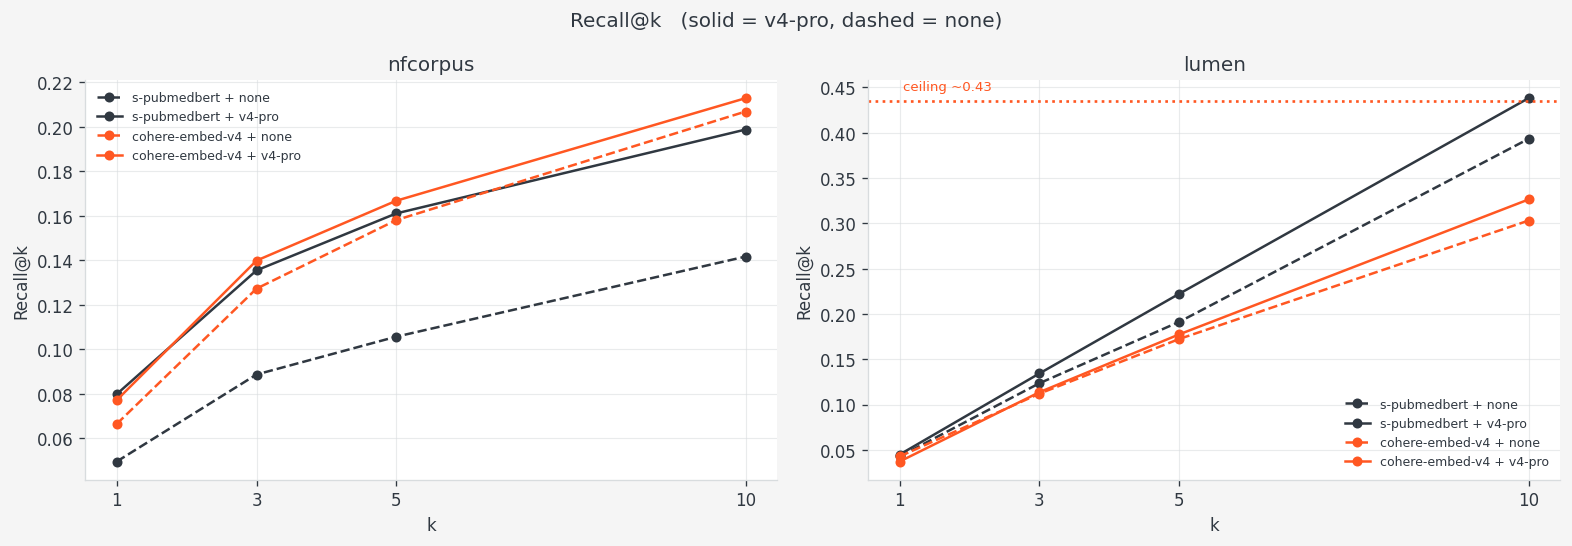

In [ ]:
ks = [1, 3, 5, 10]
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.6*len(DATASETS), 4.6), squeeze=False)
for ax, ds in zip(axes[0], DATASETS):
    sub = combined[combined.dataset == ds]
    for emb in EMB_ORDER:
        for r_ in ["none", "rerank-v4.0-pro"]:
            m = sub[(sub.embedder == emb) & (sub.reranker == r_)]
            if m.empty: continue
            row = m.iloc[0]
            ax.plot(ks, [row[f"R@{k}"] for k in ks], marker="o", ms=5,
                    ls="-" if r_ == "rerank-v4.0-pro" else "--",
                    color=C_EMB[emb], label=f"{emb} + {SHORT[r_]}")
    if ds == "lumen":
        ax.axhline(LUMEN_R10_CEIL, color=T["accent"], ls=":", lw=1.6)
        ax.text(1.05, LUMEN_R10_CEIL + .012, f"ceiling ~{LUMEN_R10_CEIL:.2f}",
                fontsize=8, color=T["accent"])
    ax.set_xticks(ks); ax.set_xlabel("k"); ax.set_ylabel("Recall@k"); ax.set_title(ds)
    ax.legend(fontsize=7.5)
fig.suptitle("Recall@k   (solid = v4-pro, dashed = none)", fontsize=12, color=T["ink"])
fig.tight_layout(); plt.show()

In [ ]:
if "lumen" in DATASETS:
    best = combined[combined.dataset == "lumen"]["R@10"].max()
    print(f"best R@10 {best:.4f}  |  ceiling {LUMEN_R10_CEIL:.4f}  |  {best/LUMEN_R10_CEIL:.1%} of ceiling")

best R@10 0.4381  |  ceiling 0.4348  |  100.8% of ceiling


---
## 8 - Metric discriminability

Spread between best and worst arm. Small = metric cannot separate them.

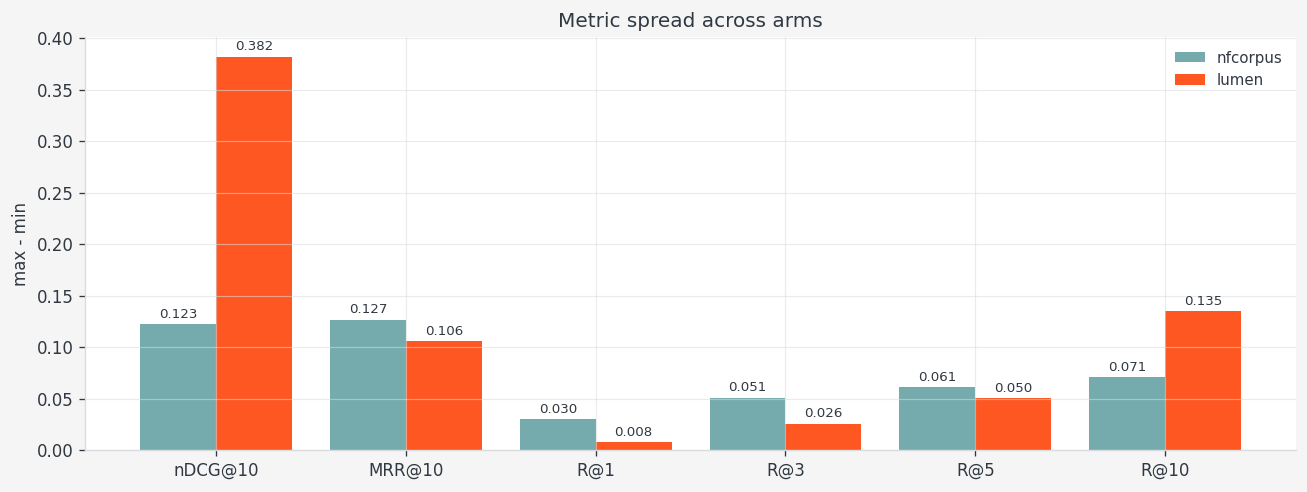

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.2))
xs = np.arange(len(METRICS)); w = .8/len(DATASETS)
for i, ds in enumerate(DATASETS):
    sub = combined[combined.dataset == ds]
    b = ax.bar(xs + i*w, [sub[m].max() - sub[m].min() for m in METRICS], w,
               color=C_DS[ds], label=ds)
    ax.bar_label(b, fmt="%.3f", fontsize=8, padding=2, color=T["ink"])
ax.set_xticks(xs + w*(len(DATASETS)-1)/2); ax.set_xticklabels(METRICS)
ax.set_ylabel("max - min"); ax.set_title("Metric spread across arms")
ax.legend(fontsize=9)
fig.tight_layout(); plt.show()

Report nDCG@10. LUMEN MRR and R@1 are saturated.

---
## 9 - Duo comparison, bootstrap CI

`s-pubmedbert + medcpt` vs `cohere-embed-v4 + rerank-v4.0-pro`.

In [ ]:
CI = {"nfcorpus": (0.0728, 0.0553, 0.0912),
      "lumen":    (0.1467, 0.0716, 0.2256)}
CI_SOURCE = "reported"

try:
    import pytrec_eval
    def _pq(res, qd, qids):
        ev = pytrec_eval.RelevanceEvaluator(
            {q:{d:int(s) for d,s in v.items()} for q,v in qd.items()}, {"ndcg_cut.10"})
        sc = ev.evaluate({q:{d:float(s) for d,s in v.items()} for q,v in res.items()})
        return np.array([sc[q]["ndcg_cut_10"] for q in qids if q in sc])
    def _boot(a, b, n=10_000, seed=0):
        rng = np.random.default_rng(seed); d = a - b
        idx = rng.integers(0, len(d), size=(n, len(d)))
        return d.mean(), *np.percentile(d[idx].mean(axis=1), [2.5, 97.5])
    _r = {}
    for _ds, _g, _q, _ids in [("nfcorpus", grid_nf, qrels_nf, query_ids_nf),
                              ("lumen",    grid_lu, qrels_lu, query_ids_lu)]:
        _r[_ds] = _boot(_pq(_g[("cohere-embed-v4","rerank-v4.0-pro")], _q, _ids),
                        _pq(_g[("s-pubmedbert","medcpt")],             _q, _ids))
    CI, CI_SOURCE = _r, "recomputed"
except Exception:
    pass

print(f"CI: {CI_SOURCE}\n")
for ds in DATASETS:
    d, lo, hi = CI[ds]
    print(f"{ds:10s} {d:+.4f}  [{lo:+.4f}, {hi:+.4f}]  width {hi-lo:.4f}  "
          f"{'significant' if lo>0 or hi<0 else 'not significant'}")

CI: reported

nfcorpus   +0.0728  [+0.0553, +0.0912]  width 0.0359  significant
lumen      +0.1467  [+0.0716, +0.2256]  width 0.1540  significant


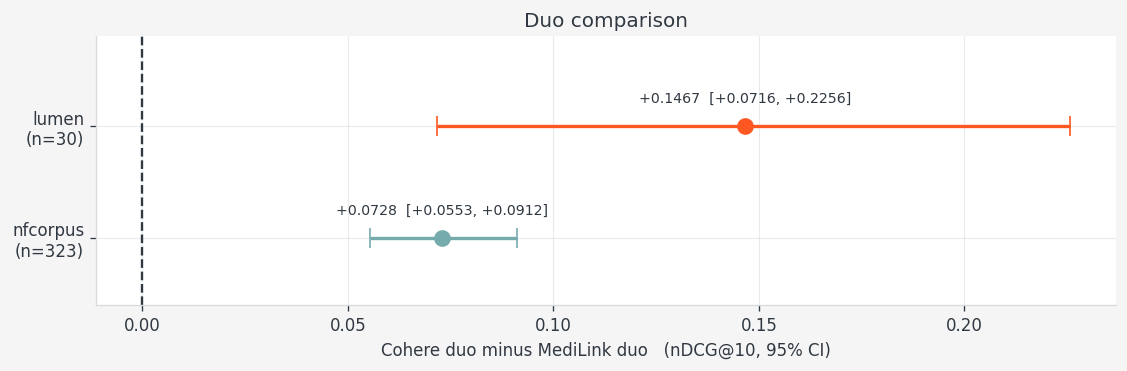

In [ ]:
fig, ax = plt.subplots(figsize=(9.5, 3.2))
for i, ds in enumerate(DATASETS):
    d, lo, hi = CI[ds]
    ax.errorbar(d, i, xerr=[[d-lo],[hi-d]], fmt="o", ms=9, capsize=6, lw=2, color=C_DS[ds])
    ax.annotate(f"{d:+.4f}  [{lo:+.4f}, {hi:+.4f}]", (d, i),
                textcoords="offset points", xytext=(0,14), ha="center",
                fontsize=8.5, color=T["ink"])
ax.axvline(0, color=T["ink"], ls="--", lw=1.4)
ax.set_yticks(range(len(DATASETS)))
ax.set_yticklabels([f"{d}\n(n={N_QUERIES.get(d,'?')})" for d in DATASETS])
ax.set_ylim(-.6, len(DATASETS)-.2)
ax.set_xlabel("Cohere duo minus MediLink duo   (nDCG@10, 95% CI)")
ax.set_title("Duo comparison")
fig.tight_layout(); plt.show()

Both exclude zero. LUMEN's interval is 4x wider (n=30).

---
## 10 - Which swap did the work?

The duo test changes embedder and reranker together. Separating them.

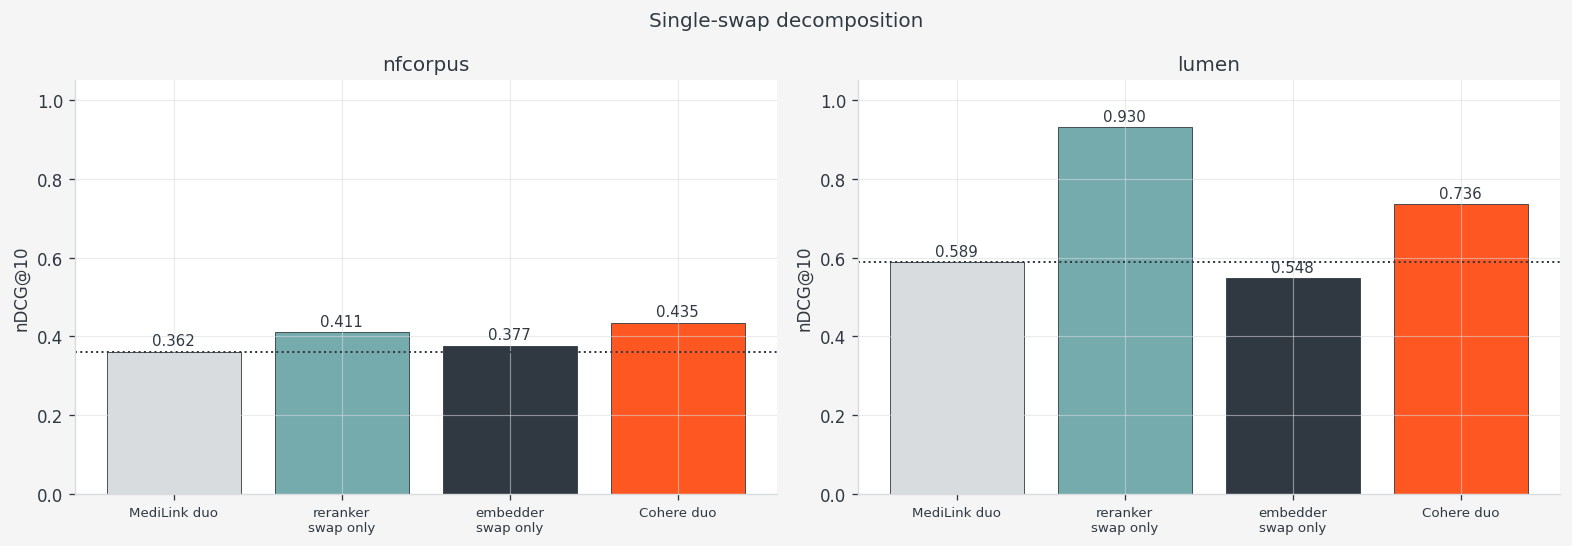

,reranker only,embedder only,both,best in grid
dataset,,,,
nfcorpus,0.0491,0.0148,0.0728,0.4347
lumen,0.3409,-0.0410,0.1467,0.9298


In [ ]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.6*len(DATASETS), 4.6), squeeze=False)
decomp = []
BARC = [T["grid"], T["muted"], T["ink"], T["accent"]]
for ax, ds in zip(axes[0], DATASETS):
    p = piv(ds)
    vals = [p.loc["s-pubmedbert","medcpt"], p.loc["s-pubmedbert","rerank-v4.0-pro"],
            p.loc["cohere-embed-v4","medcpt"], p.loc["cohere-embed-v4","rerank-v4.0-pro"]]
    names = ["MediLink duo", "reranker\nswap only", "embedder\nswap only", "Cohere duo"]
    b = ax.bar(names, vals, color=BARC, edgecolor=T["ink"], linewidth=.5)
    ax.bar_label(b, fmt="%.3f", fontsize=9, padding=2, color=T["ink"])
    ax.axhline(vals[0], color=T["ink"], ls=":", lw=1.2)
    ax.set_ylim(0, 1.05); ax.set_ylabel("nDCG@10"); ax.set_title(ds)
    ax.tick_params(axis="x", labelsize=8)
    decomp.append({"dataset":ds, "reranker only":round(vals[1]-vals[0],4),
                   "embedder only":round(vals[2]-vals[0],4),
                   "both":round(vals[3]-vals[0],4), "best in grid":round(p.values.max(),4)})
fig.suptitle("Single-swap decomposition", fontsize=12, color=T["ink"])
fig.tight_layout(); plt.show()

pd.DataFrame(decomp).set_index("dataset")

On lumen the swaps cancel: reranker +0.341, embedder -0.041. Best cell overall is
`s-pubmedbert + v4-pro` (0.930), which is neither duo.

---
## 11 - Combined ranking

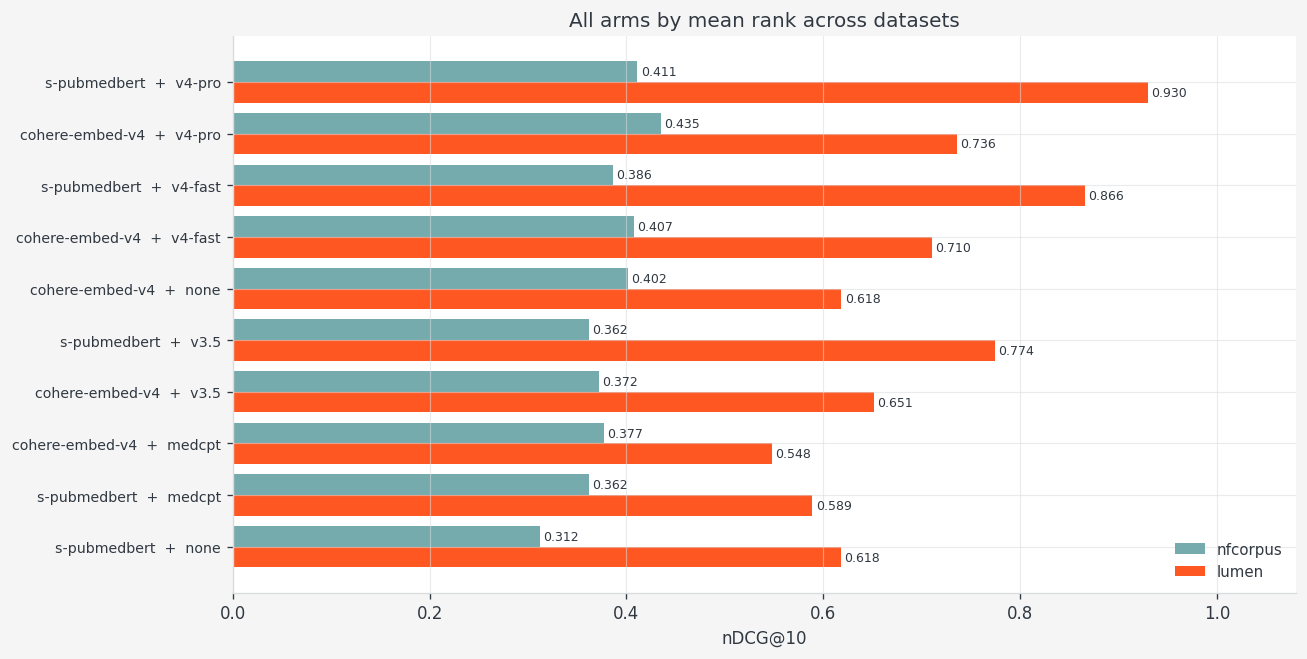

dataset,lumen,nfcorpus,mean_rank
arm,,,
s-pubmedbert + v4-pro,0.9298,0.4110,1.5
cohere-embed-v4 + v4-pro,0.7356,0.4347,2.5
s-pubmedbert + v4-fast,0.8657,0.3860,3.5
cohere-embed-v4 + v4-fast,0.7102,0.4074,4.0
cohere-embed-v4 + none,0.6183,0.4016,5.5
s-pubmedbert + v3.5,0.7744,0.3617,6.0
cohere-embed-v4 + v3.5,0.6511,0.3720,6.5
cohere-embed-v4 + medcpt,0.5479,0.3767,8.0
s-pubmedbert + medcpt,0.5889,0.3619,8.5


In [ ]:
rank = (combined.assign(arm=lambda d: d.embedder + "  +  " + d.reranker.map(SHORT))
        .pivot(index="arm", columns="dataset", values="nDCG@10"))
rank["mean_rank"] = rank[DATASETS].rank(ascending=False).mean(axis=1)
rank = rank.sort_values("mean_rank")

fig, ax = plt.subplots(figsize=(11, 5.6))
ys = np.arange(len(rank)); h = .8/len(DATASETS)
for i, ds in enumerate(DATASETS):
    b = ax.barh(ys + i*h, rank[ds].values, h, color=C_DS[ds], label=ds)
    ax.bar_label(b, fmt="%.3f", fontsize=7.5, padding=2, color=T["ink"])
ax.set_yticks(ys + h*(len(DATASETS)-1)/2); ax.set_yticklabels(rank.index, fontsize=8.5)
ax.invert_yaxis(); ax.set_xlim(0, 1.08); ax.set_xlabel("nDCG@10")
ax.set_title("All arms by mean rank across datasets")
ax.legend(fontsize=9, loc="lower right")
fig.tight_layout(); plt.show()

rank.round(4)

In [ ]:
cons = (combined.assign(arm=lambda d: d.embedder + " + " + d.reranker.map(SHORT))
        .pivot(index="arm", columns="dataset", values="nDCG@10"))
for ds in DATASETS:
    cons[f"rank_{ds}"] = cons[ds].rank(ascending=False).astype(int)
cons["gap"] = (cons[f"rank_{DATASETS[0]}"] - cons[f"rank_{DATASETS[1]}"]).abs()
cons.sort_values("gap", ascending=False)[[f"rank_{d}" for d in DATASETS] + ["gap"]]

dataset,rank_nfcorpus,rank_lumen,gap
arm,,,
s-pubmedbert + v3.5,9,3,6
cohere-embed-v4 + medcpt,6,10,4
cohere-embed-v4 + none,4,7,3
cohere-embed-v4 + v4-pro,1,4,3
s-pubmedbert + v4-fast,5,2,3
cohere-embed-v4 + v4-fast,3,5,2
s-pubmedbert + none,10,8,2
cohere-embed-v4 + v3.5,7,6,1
s-pubmedbert + medcpt,8,9,1


Large `gap` = the two datasets disagree about that arm.